### Homework: Clustering for Customer Personality Analysis

#### Context
In this homework we use clustering algorithms to analyse customer profiles (Customer Personality Analysis).

Customer Personality Analysis means looking at the different groups (segments) of a company's customers. It helps a business understand its customers better and adapt its products to the needs, habits and interests of each type of customer.

For example, instead of spending money to advertise a new product to every customer in the database, the business can find the group of customers most likely to buy it and focus its marketing only on that group.

#### Task
Use the data in `marketing_campaign.csv` to cluster the customers and find customer segments.

#### Input data
The dataset has these columns:

**About the customer:**
- `ID`: unique customer ID
- `Year_Birth`: year the customer was born
- `Education`: customer's education level
- `Marital_Status`: customer's marital status
- `Income`: yearly household income
- `Kidhome`: number of small children in the household
- `Teenhome`: number of teenagers in the household
- `Dt_Customer`: date the customer signed up with the company
- `Recency`: days since the customer's last purchase
- `Complain`: 1 if the customer complained in the last 2 years, otherwise 0

**Products:**
- `MntWines`: money spent on wine in the last 2 years
- `MntFruits`: money spent on fruit in the last 2 years
- `MntMeatProducts`: money spent on meat in the last 2 years
- `MntFishProducts`: money spent on fish in the last 2 years
- `MntSweetProducts`: money spent on sweets in the last 2 years
- `MntGoldProds`: money spent on gold in the last 2 years

**Promotions:**
- `NumDealsPurchases`: number of purchases made with a discount
- `AcceptedCmp1`: 1 if the customer accepted the offer in campaign 1, otherwise 0
- `AcceptedCmp2`: 1 if the customer accepted the offer in campaign 2, otherwise 0
- `AcceptedCmp3`: 1 if the customer accepted the offer in campaign 3, otherwise 0
- `AcceptedCmp4`: 1 if the customer accepted the offer in campaign 4, otherwise 0
- `AcceptedCmp5`: 1 if the customer accepted the offer in campaign 5, otherwise 0
- `Response`: 1 if the customer accepted the offer in the latest campaign, otherwise 0

**How the customer shops:**
- `NumWebPurchases`: number of purchases on the company website
- `NumCatalogPurchases`: number of purchases from the catalog
- `NumStorePurchases`: number of purchases in physical stores
- `NumWebVisitsMonth`: number of visits to the website in the last month

**Task 1.** Load `marketing_campaign.csv` into a Pandas DataFrame and show the basic information: how many rows and columns there are, the data type of each column, and how many values are missing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn import metrics
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('marketing_campaign.csv', sep='\t')

print(f'Rows: {df.shape[0]}, columns: {df.shape[1]}')
df.info()

print('\nMissing values:')
print(df.isna().sum()[df.isna().sum() > 0])
df.head()

Rows: 2240, columns: 29
<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


**Conclusion.** The dataset has **2240 rows and 29 columns**. 26 columns are numbers (25 `int64` and 1 `float64`, which is `Income`). 3 columns are text: `Education`, `Marital_Status` and `Dt_Customer` (a date that was read as text). Only `Income` has missing values: **24 of them** (about 1%).

**Task 2.** Fill in the missing values, keeping in mind that our goal is clustering. Explain why you chose this way of filling them.

In [2]:
# Only Income has missing values (24 out of 2240, about 1%).
# Income has a few very large values, so the median is safer than the mean.
# Income depends a lot on education, so we fill with the median income of the same Education group.
print('Median Income by education level:')
print(df.groupby('Education')['Income'].median())

df['Income'] = df['Income'].fillna(df.groupby('Education')['Income'].transform('median'))
print('\nMissing values after filling:', df['Income'].isna().sum())

Median Income by education level:
Education
2n Cycle      46805.0
Basic         20744.0
Graduation    52028.5
Master        50943.0
PhD           55212.0
Name: Income, dtype: float64

Missing values after filling: 0


**Conclusion.** We should not just delete rows with missing income, because then those customers would not get a cluster. Filling with 0 is also a bad idea: it would create a fake group of "zero income" customers.

Income has some extremely large values (the maximum is 666,666), so the **median** is a safer choice than the mean. Income also depends a lot on education (median ≈ 20.7k for `Basic` vs ≈ 55.2k for `PhD`). So we fill each missing value with **the median income of customers with the same education level**. This gives a more realistic guess than one overall number.

**Task 3.** Some columns contain categories (text) and one column contains a date. How would you prepare these columns so a clustering algorithm can use them?

Write the code that converts the category columns and the date column into features that you think are useful for clustering.

In [3]:
# --- Sign-up date -> number of days the customer has been with the company ---
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')
ref_date = df['Dt_Customer'].max()
df['Customer_Days'] = (ref_date - df['Dt_Customer']).dt.days

# --- Birth year -> age (at the latest sign-up date in the data) ---
df['Age'] = ref_date.year - df['Year_Birth']

# --- Education -> a number from 0 to 4 (education levels have a natural order) ---
edu_map = {'Basic': 0, '2n Cycle': 1, 'Graduation': 2, 'Master': 3, 'PhD': 4}
df['Education_Level'] = df['Education'].map(edu_map)

# --- Marital_Status -> lives with a partner (1) or alone (0) ---
# 'Alone', 'Absurd', 'YOLO' are rare or junk values, we count them as "alone"
df['Has_Partner'] = df['Marital_Status'].isin(['Married', 'Together']).astype(int)

# --- Extra summary features that help describe customers ---
df['Children'] = df['Kidhome'] + df['Teenhome']
df['Family_Size'] = 1 + df['Has_Partner'] + df['Children']
mnt_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
num_cols = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
df['Total_Spent'] = df[mnt_cols].sum(axis=1)
df['Total_Purchases'] = df[num_cols].sum(axis=1)
df['Total_Accepted'] = df[['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']].sum(axis=1)

# Drop ID, the original columns we already converted, and Z_CostContact / Z_Revenue (they never change)
print('Unique values of Z_CostContact, Z_Revenue:', df['Z_CostContact'].unique(), df['Z_Revenue'].unique())
drop_cols = ['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Dt_Customer', 'Z_CostContact', 'Z_Revenue']
data = df.drop(columns=drop_cols)
print(data.shape)
data.head()

Unique values of Z_CostContact, Z_Revenue: [3] [11]
(2240, 31)


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,Response,Customer_Days,Age,Education_Level,Has_Partner,Children,Family_Size,Total_Spent,Total_Purchases,Total_Accepted
0,58138.0,0,0,58,635,88,546,172,88,88,...,1,663,57,2,0,0,1,1617,22,1
1,46344.0,1,1,38,11,1,6,2,1,6,...,0,113,60,2,0,2,3,27,4,0
2,71613.0,0,0,26,426,49,127,111,21,42,...,0,312,49,2,1,0,2,776,20,0
3,26646.0,1,0,26,11,4,20,10,3,5,...,0,139,30,2,1,1,3,53,6,0
4,58293.0,1,0,94,173,43,118,46,27,15,...,0,161,33,4,1,1,3,422,14,0


**Conclusion.** How we prepared the text and date columns:
- `Dt_Customer` → `Customer_Days`: how many days the person has been a customer. The algorithm can't use a date directly, but "how long they've been with us" is useful.
- `Year_Birth` → `Age`, because age is easier to understand.
- `Education` → `Education_Level` (0 to 4). Education levels have a natural order (Basic < ... < PhD), so a single number works well. One-hot encoding would add 5 extra columns for no real benefit.
- `Marital_Status` → `Has_Partner` (1 for Married/Together, otherwise 0). There are 8 categories, and some (`Alone`, `Absurd`, `YOLO`) are junk. What really matters is whether the customer lives with a partner.
- New summary features: `Children`, `Family_Size`, `Total_Spent`, `Total_Purchases`, `Total_Accepted`. Each one combines several similar columns into one simple, meaningful number.
- Removed `ID` (it means nothing), and `Z_CostContact` and `Z_Revenue`, which have the same value (3 and 11) for every customer.

**Task 4.**
1. Put the data you are going to cluster into a variable `X`.
2. Run KMeans with 3 clusters.
3. Calculate the silhouette score for this clustering.

In [4]:
X = data.copy()

kmeans = KMeans(n_clusters=3, n_init='auto', random_state=42)
labels = kmeans.fit_predict(X)
data['cluster_raw'] = labels

s = metrics.silhouette_score(X, labels, metric='euclidean')
print(f'Silhouette Coefficient (KMeans, 3 clusters, no scaling): {s:.3f}')
print(pd.Series(labels).value_counts().sort_index())

Silhouette Coefficient (KMeans, 3 clusters, no scaling): 0.598
0    1162
1       1
2    1077
Name: count, dtype: int64


**Conclusion.** A silhouette score of **0.598** looks good, but it's misleading. One of the three clusters has **only one customer** (the one with income 666,666). Without scaling, `Income` has values thousands of times bigger than the other columns, so it decides almost everything. KMeans basically splits customers by income, and the outlier becomes its own cluster.

**Task 5.** Visualise the clusters you found together with the data, and analyse them. We have more than 2 or 3 features, so think about which features to plot so the chart is useful. Pay special attention to customer income and how customers interact with the store (number of purchases, etc.).

`plotly.express.scatter_3d` is handy for a 3D scatter plot, but you can use any visualisation method you like. Describe what you see: do the clusters make sense?

In [5]:
fig = px.scatter_3d(
    data, x='Income', y='Total_Spent', z='Total_Purchases',
    color=data['cluster_raw'].astype(str),
    opacity=0.6, title='KMeans (3 clusters, no scaling)'
)
fig.update_traces(marker_size=3)
fig.show()

profile_cols = ['Income', 'Total_Spent', 'Total_Purchases', 'NumWebVisitsMonth', 'NumDealsPurchases',
                'Children', 'Age', 'Recency', 'Total_Accepted']
data.groupby('cluster_raw')[profile_cols].mean().round(1)

,Income,Total_Spent,Total_Purchases,NumWebVisitsMonth,NumDealsPurchases,Children,Age,Recency,Total_Accepted
cluster_raw,,,,,,,,,
0,34936.6,173.6,7.4,6.6,2.4,1.2,43.1,49.3,0.2
1,666666.0,62.0,7.0,6.0,4.0,1.0,37.0,23.0,0.0
2,70343.9,1072.6,18.1,3.9,2.2,0.7,47.4,48.9,0.7


**Conclusion.** In the 3D chart (`Income`, `Total_Spent`, `Total_Purchases`) the clusters are split **almost only by income**:
- **Cluster 0** (1162 customers): income ≈ 35k, spend ≈ 174, ≈ 7 purchases, more children (1.2), visit the website more often (6.6 visits/month).
- **Cluster 2** (1077 customers): income ≈ 70k, spend ≈ 1073, ≈ 18 purchases, accept campaign offers more often.
- **Cluster 1**: just one outlier (income 666,666 but spent only 62).

Splitting customers into "lower income" and "higher income" makes some sense, because income and spending go together. But the third cluster is useless, and other features (children, age, how they shop) have almost no effect. So this clustering doesn't use most of the information in the data.

**Task 6.** Scale the data (StandardScaler or MinMaxScaler), run KMeans with 3 clusters again and calculate the silhouette score. Compare the result with the experiment without scaling.

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans_sc = KMeans(n_clusters=3, n_init='auto', random_state=42)
labels_sc = kmeans_sc.fit_predict(X_scaled)
data['cluster_scaled'] = labels_sc

s_sc = metrics.silhouette_score(X_scaled, labels_sc)
print(f'Silhouette (KMeans, 3 clusters, StandardScaler): {s_sc:.3f}')
print(f'Silhouette (no scaling, for comparison): {s:.3f}')
print(pd.Series(labels_sc).value_counts().sort_index())

fig = px.scatter_3d(
    data, x='Income', y='Total_Spent', z='Total_Purchases',
    color=data['cluster_scaled'].astype(str),
    opacity=0.6, title='KMeans (3 clusters, StandardScaler)'
)
fig.update_traces(marker_size=3)
fig.show()

data.groupby('cluster_scaled')[profile_cols].mean().round(1)

Silhouette (KMeans, 3 clusters, StandardScaler): 0.175
Silhouette (no scaling, for comparison): 0.598
0    1077
1     502
2     661
Name: count, dtype: int64


,Income,Total_Spent,Total_Purchases,NumWebVisitsMonth,NumDealsPurchases,Children,Age,Recency,Total_Accepted
cluster_scaled,,,,,,,,,
0,35680.7,104.0,6.0,6.4,2.1,1.3,42.8,49.5,0.2
1,78088.6,1430.2,19.3,2.7,1.2,0.1,45.1,49.9,1.2
2,59598.8,797.4,18.0,5.5,3.5,1.1,49.2,47.8,0.3


**Conclusion.** After `StandardScaler` the silhouette score dropped from **0.598 to 0.175**, but the clusters are actually **more meaningful**:
- the earlier score was high only because `Income` dominated and one cluster was a single outlier;
- now every feature counts equally, and the clusters have sensible sizes (1077 / 502 / 661);
- the groups are easy to describe:
  - **0**: lower income (≈ 36k), spend little, have children;
  - **1**: high income (≈ 78k), almost no children, spend the most (≈ 1430), accept campaign offers most often, rarely use discounts;
  - **2**: middle income (≈ 60k), a bit older, with children (mostly teenagers). They buy a lot and **use discounts the most** (3.5 discounted purchases).

The low score means customers don't form clearly separated groups; they form one big "cloud". That's normal for customer behaviour data. Also, silhouette scores calculated on scaled and unscaled data can't be compared directly.

**Task 7.** In the charts from the previous step you may have noticed some outliers. Deal with them (you can remove these rows or come up with another approach).

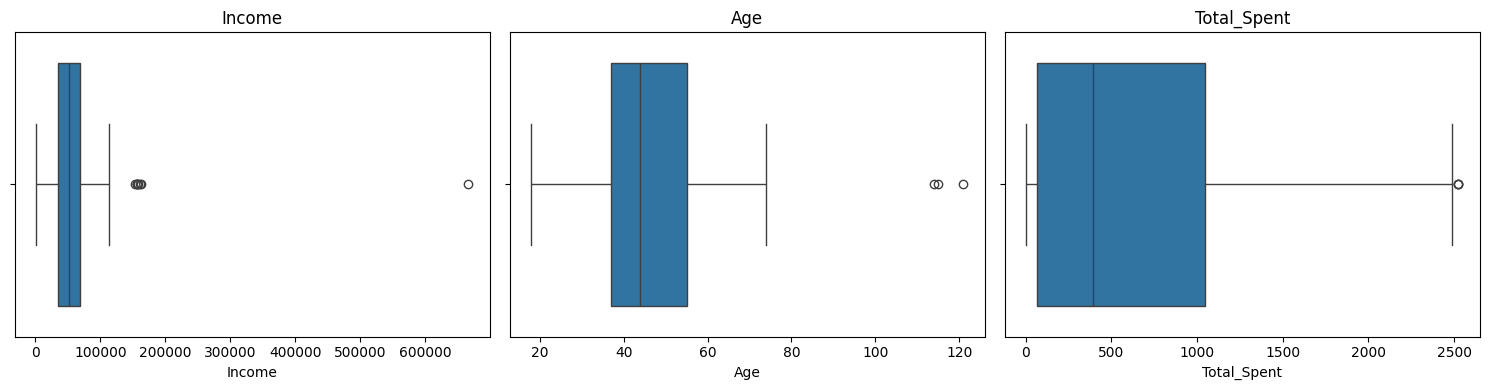

        Income  Total_Spent  Total_Purchases
2233  666666.0           62                7
617   162397.0          107                1
687   160803.0         1717               29
1300  157733.0           59                2
164   157243.0         1608               22
1653  157146.0         1730               28
2132  156924.0            8                0
655   153924.0            6                0
      Age
239   121
339   115
192   114
1950   74
424    73
Rows removed: 11
(2229, 31)


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Income', 'Age', 'Total_Spent']):
    sns.boxplot(x=data[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print(data.sort_values('Income', ascending=False)[['Income', 'Total_Spent', 'Total_Purchases']].head(8))
print(data.sort_values('Age', ascending=False)[['Age']].head(5))

# Outliers: income 666666 (clearly a mistake - this person spent almost nothing)
# and age > 100 (born in 1893-1900). There are very few such rows, so we remove them.
# Some other customers with income ~150-160k buy almost nothing, which also looks wrong,
# so we keep only Income < 150000.
mask = (data['Income'] < 150000) & (data['Age'] < 100)
print('Rows removed:', (~mask).sum())

data_clean = data[mask].drop(columns=['cluster_raw', 'cluster_scaled']).reset_index(drop=True)
X_clean = data_clean.copy()
X_clean_scaled = StandardScaler().fit_transform(X_clean)
print(X_clean.shape)

**Conclusion.** The box plots and sorted tables show two kinds of outliers:
- `Income` = 666,666: clearly a data error (this customer spent only 62). There are also a few customers with income over 150k who buy almost nothing.
- `Age` = 114–121 (born 1893–1900): impossible values, most likely typing mistakes.

There are only **11 such rows out of 2240** (less than 0.5%), so the simplest fix is to **remove them** (`Income < 150000` and `Age < 100`). Another option would be to cap the values at a limit, but for obvious errors removing them is cleaner. After cleaning we have 2229 customers, and we recalculated the scaled version of the data.

**Task 8.** Use the Elbow method to find the best number of clusters, then train KMeans with that number. Calculate the silhouette score and visualise the clusters. You can choose whether to use scaled or unscaled data, or try both.

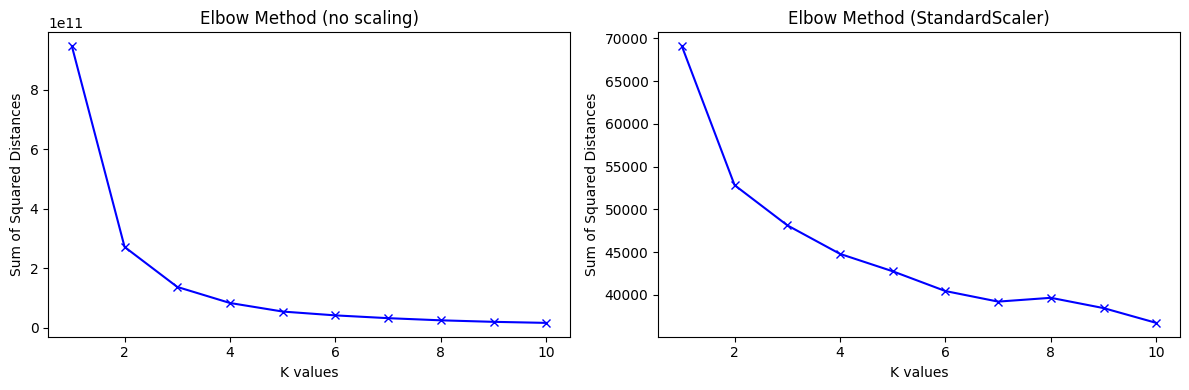

k=2: silhouette raw=0.603, scaled=0.252
k=3: silhouette raw=0.550, scaled=0.177
k=4: silhouette raw=0.533, scaled=0.178


k=5: silhouette raw=0.536, scaled=0.182
k=6: silhouette raw=0.517, scaled=0.124

Silhouette (KMeans, k=2, scaled data, no outliers): 0.252
cluster_km
0     899
1    1330
Name: count, dtype: int64


,Income,Total_Spent,Total_Purchases,NumWebVisitsMonth,NumDealsPurchases,Children,Age,Recency,Total_Accepted
cluster_km,,,,,,,,,
0,70784.3,1230.3,19.7,3.8,2.0,0.5,47.0,49.4,0.8
1,38673.1,183.3,7.7,6.4,2.5,1.3,43.8,48.9,0.2


In [8]:
def elbow(X_, title):
    K = range(1, 11)
    inertia = [KMeans(n_clusters=k, n_init='auto', random_state=42).fit(X_).inertia_ for k in K]
    plt.plot(K, inertia, 'bx-')
    plt.xlabel('K values')
    plt.ylabel('Sum of Squared Distances')
    plt.title(title)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); elbow(X_clean, 'Elbow Method (no scaling)')
plt.subplot(1, 2, 2); elbow(X_clean_scaled, 'Elbow Method (StandardScaler)')
plt.tight_layout()
plt.show()

for k in range(2, 7):
    l_raw = KMeans(n_clusters=k, n_init='auto', random_state=42).fit_predict(X_clean)
    l_sc = KMeans(n_clusters=k, n_init='auto', random_state=42).fit_predict(X_clean_scaled)
    print(f'k={k}: silhouette raw={metrics.silhouette_score(X_clean, l_raw):.3f}, '
          f'scaled={metrics.silhouette_score(X_clean_scaled, l_sc):.3f}')

K_OPT = 2  # chosen with the Elbow method (see the conclusion below)
kmeans_opt = KMeans(n_clusters=K_OPT, n_init='auto', random_state=42)
data_clean['cluster_km'] = kmeans_opt.fit_predict(X_clean_scaled)

s_opt = metrics.silhouette_score(X_clean_scaled, data_clean['cluster_km'])
print(f'\nSilhouette (KMeans, k={K_OPT}, scaled data, no outliers): {s_opt:.3f}')
print(data_clean['cluster_km'].value_counts().sort_index())

fig = px.scatter_3d(
    data_clean, x='Income', y='Total_Spent', z='Total_Purchases',
    color=data_clean['cluster_km'].astype(str),
    opacity=0.6, title=f'KMeans (k={K_OPT}, scaled data, no outliers)'
)
fig.update_traces(marker_size=3)
fig.show()

data_clean.groupby('cluster_km')[profile_cols].mean().round(1)

**Conclusion.**
- **Without scaling**, the "elbow" is clearly at **k = 2**: the error drops from about 9.5·10¹¹ to 2.7·10¹¹ and then decreases slowly. The silhouette score is high (0.603), but again the clusters are based only on `Income`.
- **With scaling**, the biggest bend is also at **k = 2**, and after that the curve goes down smoothly. The silhouette score is highest at k = 2 (**0.252**).

We chose **k = 2 on scaled data**, because then all features are taken into account. The silhouette score is **0.252**, better than 0.175 for k = 3 in Task 6 (removing outliers also helped). The two groups:
- **Cluster 0** (899): "well-off, active shoppers": income ≈ 71k, spend ≈ 1230, ≈ 20 purchases, few children (0.5), accept campaign offers more often (0.8).
- **Cluster 1** (1330): "budget-conscious families": income ≈ 39k, spend ≈ 183, ≈ 8 purchases, more children (1.3), visit the website often but buy little.

This split is easy to use in marketing: premium offers for the first group, discounts and family products for the second.

**Task 9.** Using `scipy`'s `dendrogram`, `linkage` and `fcluster`:
1. Build agglomerative hierarchical clustering with `single linkage` on unscaled data with the outliers removed.
2. Plot the dendrogram. Make sure to set `truncate_mode='lastp'` - this shortens the dendrogram. Without it the plot would be far too big, because we have much more data than in the lecture.
3. Look at the dendrogram and use `fcluster` to make flat clusterings with 2 and 3 clusters. Visualise each one and write your conclusion. Do you think either of them is good? What do you notice?
4. Calculate the silhouette score for this clustering method.

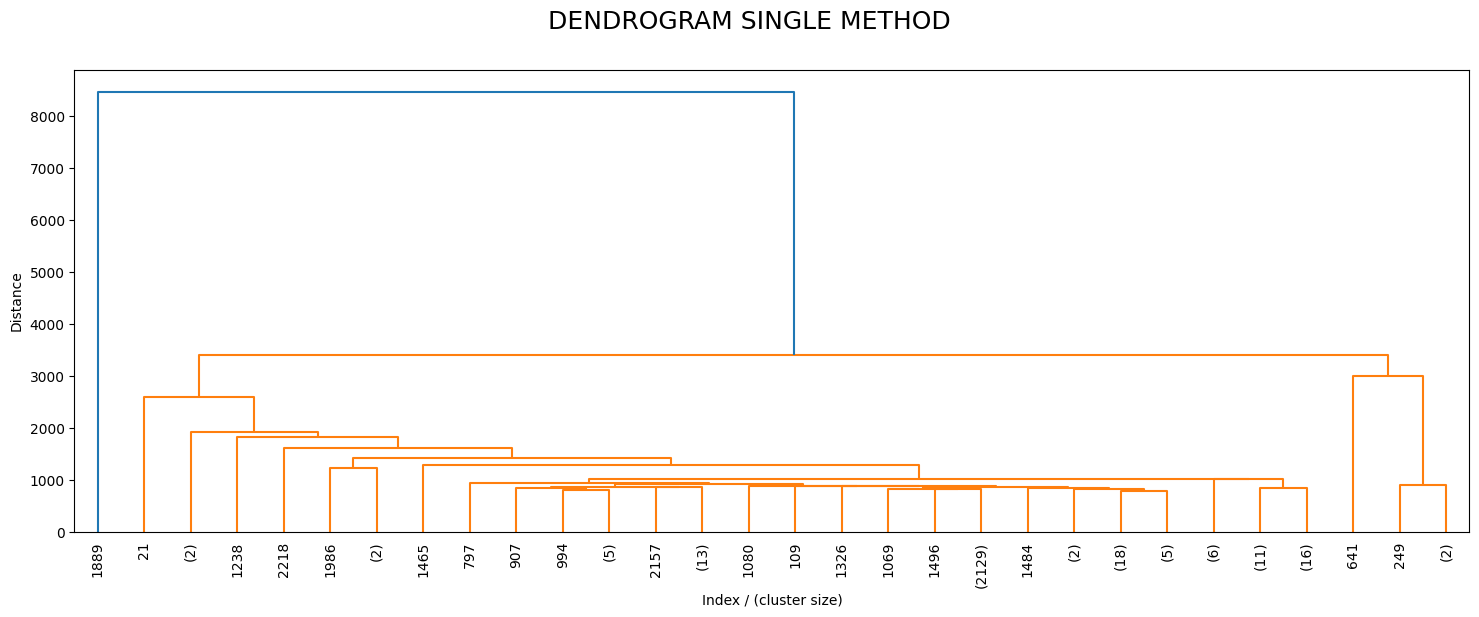

2_clust
1    2228
2       1
Name: count, dtype: int64
3_clust
1    2224
2       4
3       1
Name: count, dtype: int64


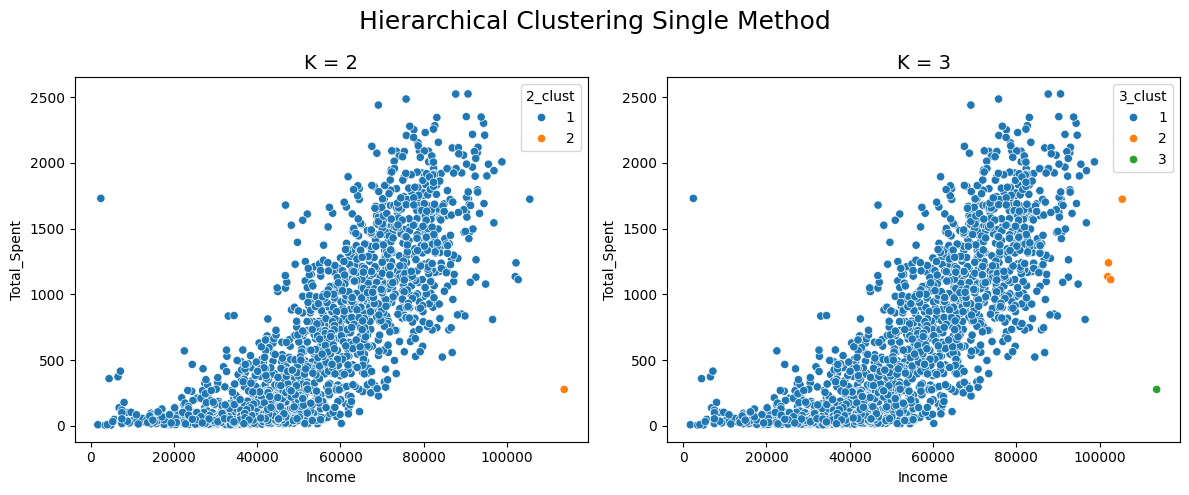

        Income  Total_Spent  Total_Purchases
124   101970.0         1135               27
201   102160.0         1240               26
249   102692.0         1112               28
641   105471.0         1724               30
1889  113734.0          277               27
Silhouette (single linkage, 2 clusters): 0.557


Silhouette (single linkage, 3 clusters): 0.450


In [9]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# 1. Single linkage on unscaled data without outliers
dist_sin = linkage(X_clean, method='single')

# 2. Dendrogram
plt.figure(figsize=(18, 6))
dendrogram(dist_sin, truncate_mode='lastp', p=30, leaf_rotation=90)
plt.xlabel('Index / (cluster size)')
plt.ylabel('Distance')
plt.suptitle('DENDROGRAM SINGLE METHOD', fontsize=18)
plt.show()

# 3. Flat clusterings with 2 and 3 clusters
data_clean['2_clust'] = fcluster(dist_sin, 2, criterion='maxclust')
data_clean['3_clust'] = fcluster(dist_sin, 3, criterion='maxclust')
print(data_clean['2_clust'].value_counts().sort_index())
print(data_clean['3_clust'].value_counts().sort_index())

plt.figure(figsize=(12, 5))
plt.suptitle('Hierarchical Clustering Single Method', fontsize=18)
plt.subplot(1, 2, 1)
plt.title('K = 2', fontsize=14)
sns.scatterplot(x='Income', y='Total_Spent', data=data_clean, hue='2_clust', palette='tab10')
plt.subplot(1, 2, 2)
plt.title('K = 3', fontsize=14)
sns.scatterplot(x='Income', y='Total_Spent', data=data_clean, hue='3_clust', palette='tab10')
plt.tight_layout()
plt.show()

print(data_clean[data_clean['3_clust'] != data_clean['3_clust'].mode()[0]][['Income', 'Total_Spent', 'Total_Purchases']])

# 4. Silhouette score
for k in [2, 3]:
    s_h = metrics.silhouette_score(X_clean, data_clean[f'{k}_clust'])
    print(f'Silhouette (single linkage, {k} clusters): {s_h:.3f}')

**Conclusion.**
- The dendrogram (`truncate_mode='lastp'`) shows the typical **chaining effect** of single linkage. Almost all points (2129 plus some small groups) are joined one by one into one big cluster at small distances (under 2000). Only a few far-away points join at large distances.
- **2 clusters**: 2228 customers + 1 customer (index 1889).
- **3 clusters**: 2224 + 4 + 1. The small group of 4 is customers with income ≈ 102–106k and many purchases, so they're simply the points farthest away by `Income`.
- Silhouette score: **0.557** (2 clusters) and **0.450** (3 clusters). It's high only because one "cluster" contains almost everyone and the data is not scaled.

**Neither clustering is useful.** They don't split customers into real groups; they only find a few extreme points by income. Single linkage joins each point to its nearest neighbour, so a dense cloud of points becomes one huge cluster. This method can help find unusual points (anomalies), but it's not good for customer segmentation.

**Task 10.**
1. Use a clustering method we haven't used yet in this homework (for example, hierarchical clustering with a different linkage, or another sklearn method).
2. Calculate the silhouette score and visualise the result. Could this clustering be useful? Explain.

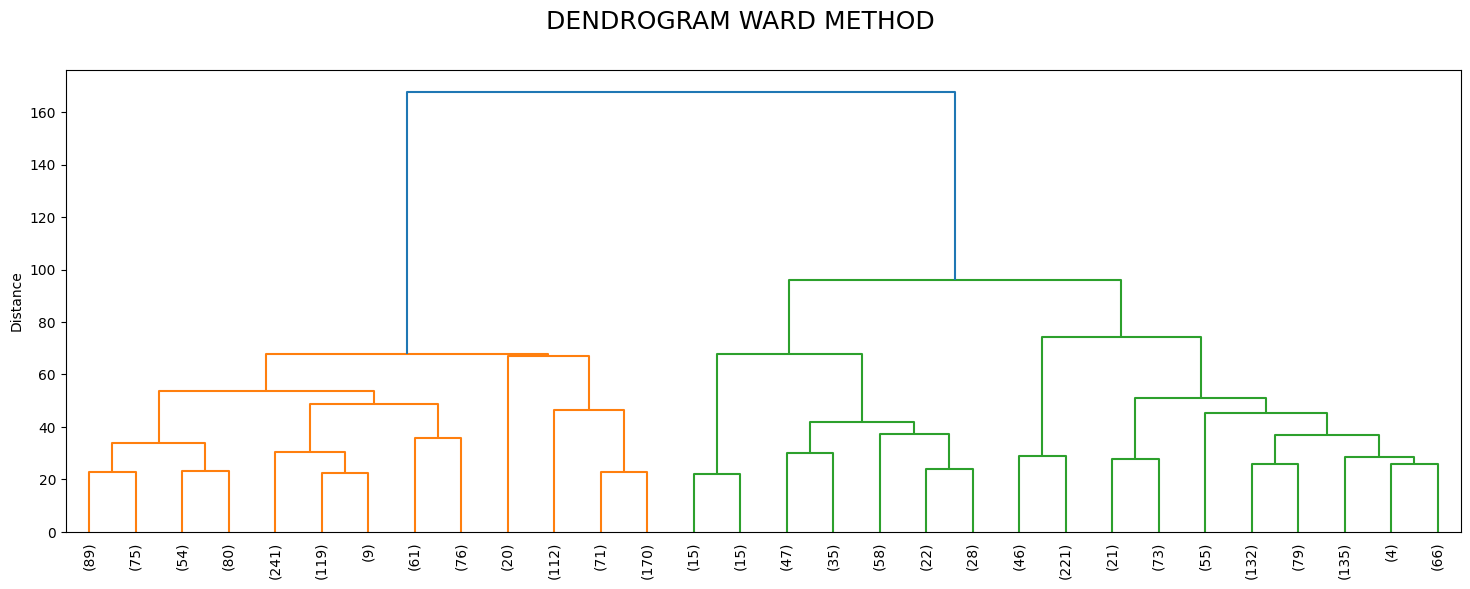

k=2: silhouette=0.205
k=3: silhouette=0.187
k=4: silhouette=0.156


k=5: silhouette=0.101

Silhouette (Agglomerative Ward, 3 clusters): 0.187
cluster_ward
0     832
1    1177
2     220
Name: count, dtype: int64


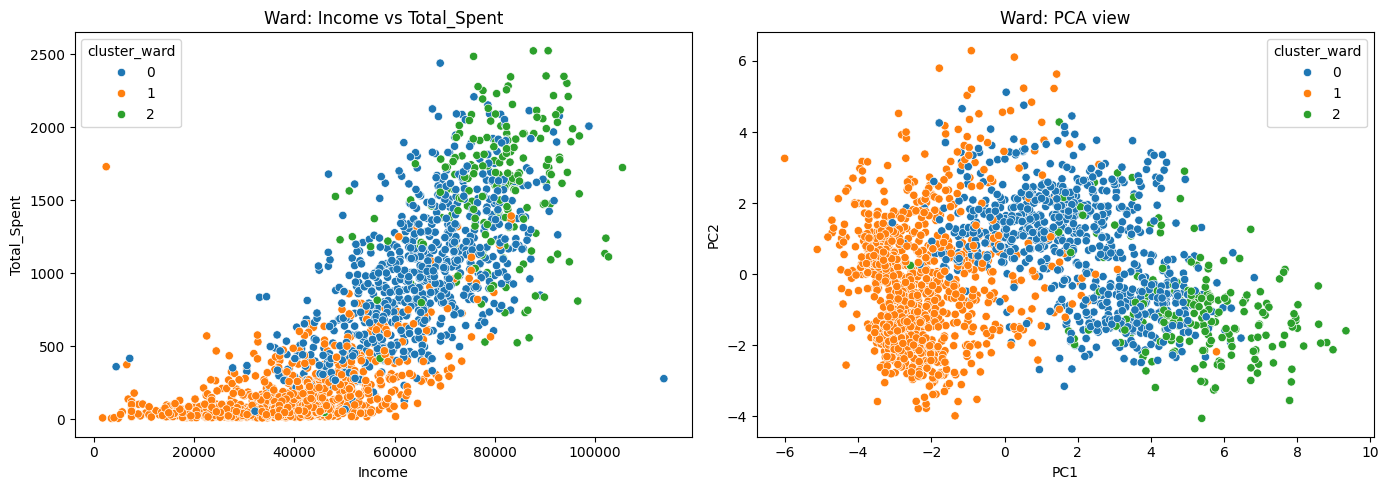

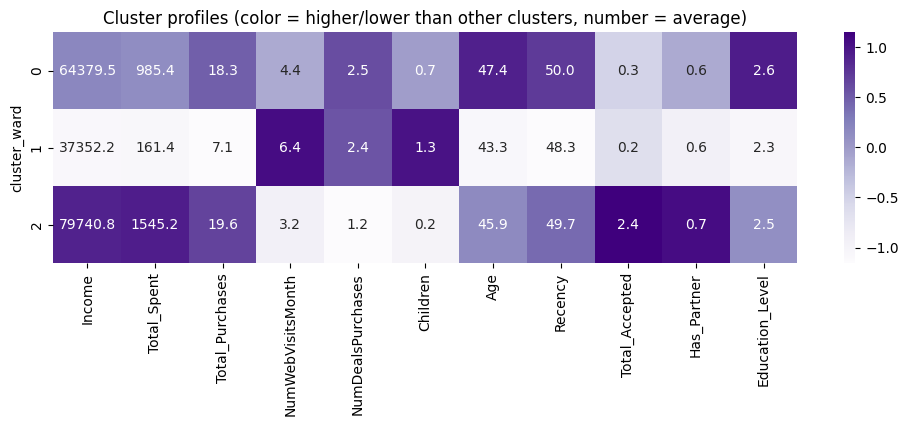

,Income,Total_Spent,Total_Purchases,NumWebVisitsMonth,NumDealsPurchases,Children,Age,Recency,Total_Accepted,Has_Partner,Education_Level
cluster_ward,,,,,,,,,,,
0,64379.5,985.4,18.3,4.4,2.5,0.7,47.4,50.0,0.3,0.6,2.6
1,37352.2,161.4,7.1,6.4,2.4,1.3,43.3,48.3,0.2,0.6,2.3
2,79740.8,1545.2,19.6,3.2,1.2,0.2,45.9,49.7,2.4,0.7,2.5


In [10]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA

# Hierarchical clustering with Ward linkage on scaled data without outliers.
# At each step Ward merges the two clusters that keep the groups as tight as possible,
# so it does not build long "chains" like single linkage does.
dist_ward = linkage(X_clean_scaled, method='ward')
plt.figure(figsize=(18, 6))
dendrogram(dist_ward, truncate_mode='lastp', p=30, leaf_rotation=90)
plt.ylabel('Distance')
plt.suptitle('DENDROGRAM WARD METHOD', fontsize=18)
plt.show()

for k in range(2, 6):
    l = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_clean_scaled)
    print(f'k={k}: silhouette={metrics.silhouette_score(X_clean_scaled, l):.3f}')

N_WARD = 3
agg = AgglomerativeClustering(n_clusters=N_WARD, linkage='ward')
data_clean['cluster_ward'] = agg.fit_predict(X_clean_scaled)
s_ward = metrics.silhouette_score(X_clean_scaled, data_clean['cluster_ward'])
print(f'\nSilhouette (Agglomerative Ward, {N_WARD} clusters): {s_ward:.3f}')
print(data_clean['cluster_ward'].value_counts().sort_index())

# Plots: key features, and a 2D PCA view of all features
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_clean_scaled)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x='Income', y='Total_Spent', data=data_clean, hue='cluster_ward', palette='tab10', ax=axes[0])
axes[0].set_title('Ward: Income vs Total_Spent')
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=data_clean['cluster_ward'], palette='tab10', ax=axes[1])
axes[1].set_title('Ward: PCA view')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
plt.tight_layout()
plt.show()

prof = data_clean.groupby('cluster_ward')[profile_cols + ['Has_Partner', 'Education_Level']].mean()
plt.figure(figsize=(12, 3))
sns.heatmap((prof - prof.mean()) / prof.std(), annot=prof.round(1), fmt='', cmap='Purples')
plt.title('Cluster profiles (color = higher/lower than other clusters, number = average)')
plt.show()
prof.round(1)

**Conclusion.** We used **hierarchical (agglomerative) clustering with Ward linkage** (`sklearn.AgglomerativeClustering`) on scaled data without outliers. At each step Ward merges the two clusters that keep the groups as tight as possible. This gives compact clusters of similar size, without the long "chains" of single linkage.

Silhouette score: k=2: 0.205, **k=3: 0.187**, k=4: 0.156. We chose **k = 3**: the score is a little lower than for k=2, but we get one extra group that is very valuable for the business:
- **Cluster 1** (1177): "budget-conscious families": income ≈ 37k, spend ≈ 161, 1.3 children, visit the website often but buy little.
- **Cluster 0** (832): "middle class": income ≈ 64k, spend ≈ 985, ≈ 18 purchases, rarely respond to campaigns (0.3).
- **Cluster 2** (220): "VIP customers who respond to marketing": highest income (≈ 80k) and spending (≈ 1545), almost no children, accepted **2.4 campaign offers** on average (8–10 times more than the other groups), rarely use discounts.

**This clustering is useful.** It finds a small group (about 10% of customers) that marketing campaigns should focus on, because these are the people who actually respond. This matches the goal of Customer Personality Analysis: don't spend the budget on everyone. The low silhouette score means the borders between groups are blurry, so think of the clusters as "typical customer profiles" rather than perfectly separate groups.